# A 2022-es energiaválság magyarországi gazdasági és inflációs hatásai

## Kezdeti kutatási terv és feltáró adatelemzés

Ez a notebook a teljes kutatás első, prezentálható munkaváltozata. Most három feladatot végzünk el:

1. pontosítjuk a kutatási kérdéseket és a hozzájuk tartozó hipotéziseket;
2. technikailag előkészítjük és dokumentáltan beolvassuk a KSH, MNB és World Bank adatait;
3. kezdeti feltáró adatelemzést (EDA) készítünk ábrákkal és táblázatokkal.

A notebook **nem tartalmaz még végleges regressziós modellt vagy oksági következtetést**. A korrelációk és az idősoros együttmozgások kutatási kiindulópontot adnak, de önmagukban nem bizonyítják, hogy az energiaárváltozás okozta az inflációt vagy a reálgazdasági változásokat.

## 1. Kutatási kérdések és hipotézisek

### Fő kutatási kérdés

**Milyen kapcsolat figyelhető meg a nemzetközi energiaárak változása, a magyar infláció és a háztartási/reálgazdasági mutatók alakulása között a 2015-től elérhető időszakban, különös tekintettel a 2022-es energiaválságra?**

### Részletes kutatási kérdések

1. Együtt mozog-e a földgáz- és kőolajárak változása a magyar fogyasztói árindex és a maginfláció későbbi alakulásával?
2. Módosíthatja-e a forint euróval szembeni árfolyamának változása az energiaárak és az infláció közötti kapcsolatot?
3. Megfigyelhető-e a háztartási fogyasztás, a kiskereskedelmi forgalom vagy az ipari teljesítmény gyengülése az energiaár-sokk időszakában?
4. Eltér-e a változók együttmozgása a 2022 előtti, a 2022-es és a 2023 utáni időszakban?

### Kezdeti hipotézisek

- **H1 – inflációs kapcsolat:** az európai földgáz- és a Brent-kőolajár emelkedése után magasabb magyar fogyasztói infláció figyelhető meg, részben késleltetve.
- **H2 – másodkörös hatás:** az energiaárak emelkedése nemcsak a fogyasztói árindexben, hanem késleltetve a maginflációban is megjelenhet.
- **H3 – árfolyamcsatorna:** a forint euróval szembeni gyengülése az energiaárak inflációs kapcsolatát erősítheti, mivel a nemzetközi energiaárak jellemzően devizában jelennek meg.
- **H4 – reálgazdasági alkalmazkodás:** az energiaár-sokk időszakában gyengébb háztartási fogyasztási és kiskereskedelmi volumenindexek, illetve mérséklődő ipari teljesítmény figyelhető meg.
- **H5 – időszakfüggőség:** a 2022-es sokk idején az együttmozgások erősebbek lehetnek, mint a sokk előtti és utáni időszakokban.

Ezek **vizsgálható munkahipotézisek**, nem előre eldöntött eredmények. A későbbi modellben a késleltetett változókat, az időszakjelzőket és az árfolyamot kontrollváltozóként kell majd kezelni. A megfigyeléses adatok alapján óvatosan, elsősorban kapcsolatként és előrejelzési teljesítményként fogalmazhatunk; oksági állításhoz további azonosítási stratégia szükséges.

## 2. Adatforrások és technikai előkészítés

Az adatfájlok három forrásból származnak:

- **KSH:** fogyasztói árindex, maginfláció, kiskereskedelmi forgalom, GDP-felhasználás és ipari termelés;
- **MNB:** jegybanki alapkamat és havi átlagos EUR/HUF árfolyam;
- **World Bank Commodity Markets:** nemzetközi energia- és nyersanyagárak havi, illetve éves adatai.

Az előzetes technikai előkészítés célja nem a végleges modelladatbázis kialakítása, hanem az, hogy a táblák különböző fejléc-, dátum- és jelölésrendszerét egységesen értelmezzük. Ezért:

- eltávolítjuk a forrásfájlok leíró fejléc- és lábjegyzetsorait;
- a dátumokat egységes hónapvégi időbélyeggé alakítjuk;
- a KSH `..` és `x` jelöléseit hiányzó értékként kezeljük;
- a százalékos változókat numerikussá alakítjuk, de nem alakítjuk át automatikusan aránnyá;
- minden átalakítást külön függvényben végzünk, hogy később ellenőrizhető és módosítható legyen.

A nyers Excel-fájlokat nem módosítjuk. A notebook a fájlok helyét a `ENERGY_PROJECT_DATA_DIR` környezeti változóból, ennek hiányában az aktuális munkakörnyezethez tartozó feltöltési könyvtárból keresi.

In [1]:
from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

REPO_DATA_DIR = Path("data")
ATTACHMENTS_DIR = Path(
    os.environ.get(
        "ENERGY_PROJECT_DATA_DIR",
        r"C:\Users\User\.copilot\workspaces\03db2f25-aa1a-4a7a-bde3-e5c30f3f66fb\attachments",
    )
)
DATA_DIR = REPO_DATA_DIR if REPO_DATA_DIR.exists() else ATTACHMENTS_DIR

def find_file(pattern):
    matches = sorted(DATA_DIR.glob(pattern))
    if not matches and DATA_DIR != ATTACHMENTS_DIR:
        matches = sorted(ATTACHMENTS_DIR.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"Nem található adatfájl: {pattern}. Keresési hely: {DATA_DIR}")
    return matches[0]

FILES = {
    "cpi": find_file("*hu0201_fogyarindex.xls"),
    "core": find_file("*hu0202_maginflacio.xls"),
    "fx": find_file("*hu0301_arfolyam.xls"),
    "base_rate": find_file("*alapkamat.xlsx"),
    "wb_monthly": find_file("*CMO-Historical-Data-Monthly_World_Bank.xlsx"),
    "wb_annual": find_file("*CMO-Historical-Data-Annual_World_Bank.xlsx"),
    "retail": find_file("*KSH_kiskereskedelmi forgalom.xlsx"),
    "gdp_consumption": find_file("*KSH_GDP felhasználás_fogyasztás.xlsx"),
    "household_consumption": find_file("*KSH_háztartások negyedéves fogyasztása.xlsx"),
    "industry": find_file("*KSH_ipari termelés.xlsx"),
    "industry_2025": find_file("*KSH_ipari termelés 2025.xlsx"),
}

inventory = pd.DataFrame(
    [{"azonosító": key, "fájl": path.name, "méret (KB)": round(path.stat().st_size / 1024, 1)}
     for key, path in FILES.items()]
)
display(inventory)

,azonosító,fájl,méret (KB)
0,cpi,f6e29de2-c164-4c2e-88e4-a0f55ae98753-hu0201_fo...,256.0
1,core,7a86c2b3-0e6b-45b9-b5f0-f97197053ef7-hu0202_ma...,145.0
2,fx,50a8f5d6-86c5-47c8-9316-f3d2e0276dba-hu0301_ar...,376.5
3,base_rate,201e5162-3f82-42d1-b379-29f06f343e4e-alapkamat...,11.5
4,wb_monthly,4254ea4d-5573-49d3-a1de-222686bd9717-CMO-Histo...,574.1
5,wb_annual,9ccc387e-f343-49a9-920c-bde25f3630d1-CMO-Histo...,390.5
6,retail,49c6d96b-de18-4de5-bdba-b51542fd66cc-KSH_kiske...,17.0
7,gdp_consumption,0dcd73f0-cedb-469f-9247-da1f1434c063-KSH_GDP f...,77.1
8,household_consumption,9431d8a1-6795-4649-bf2b-5b61f1b4fcc2-KSH_házta...,16.5
9,industry,c81ea0df-506b-417b-9151-900a6a244686-KSH_ipari...,20.6


In [2]:
MONTHS_HU = {
    "január": 1, "február": 2, "március": 3, "április": 4,
    "május": 5, "június": 6, "július": 7, "augusztus": 8,
    "szeptember": 9, "október": 10, "november": 11, "december": 12,
}

def numeric(series):
    series = pd.Series(series)
    return pd.to_numeric(
        series.astype("string").str.replace(",", ".", regex=False)
        .replace({"..": np.nan, "x": np.nan, "...": np.nan, "…": np.nan, "": np.nan}),
        errors="coerce",
    )

def parse_hu_month(value):
    if pd.isna(value):
        return pd.NaT
    text = str(value).strip().lower().replace(".", "")
    match = re.search(r"(\d{4})\s*[-./]?\s*([a-záéíóöőúüű]+)", text)
    if not match:
        return pd.NaT
    year = int(match.group(1))
    month = MONTHS_HU.get(match.group(2))
    return pd.Timestamp(year=year, month=month, day=1) + pd.offsets.MonthEnd(1) if month else pd.NaT

def month_end(values):
    return pd.to_datetime(values, errors="coerce").dt.to_period("M").dt.to_timestamp("M")

DISPLAY_NAMES = {
    "date": "Dátum",
    "cpi_yoy_pct": "Fogyasztói árindex éves változása (%)",
    "core_inflation_yoy_pct": "Maginfláció éves változása (%)",
    "core_inflation_sa_yoy_pct": "Szezonálisan igazított maginfláció (%)",
    "constant_tax_index_yoy_pct": "Változatlan adótartalmú árindex (%)",
    "household_energy_yoy_pct": "Háztartási energiaárak éves változása (%)",
    "fuel_yoy_pct": "Üzemanyagárak éves változása (%)",
    "regulated_prices_yoy_pct": "Szabályozott árak éves változása (%)",
    "brent_usd_per_bbl": "Brent kőolaj ára (USD/hordó)",
    "europe_gas_usd_per_mmbtu": "Európai földgáz ára (USD/MMBtu)",
    "australian_coal_usd_per_mt": "Ausztrál szén ára (USD/tonna)",
    "eur_huf_monthly_avg": "Havi átlagos EUR/HUF árfolyam",
    "base_rate_pct": "Jegybanki alapkamat (%)",
    "retail_calendar_adjusted_index": "Kiskereskedelem naptárhatással tisztított index",
    "retail_sa_index": "Kiskereskedelem szezonálisan és naptárhatással tisztított index",
}

def pretty_frame(frame, decimals=2, date_columns=("date",)):
    out = frame.copy()
    for column in date_columns:
        if column in out:
            out[column] = pd.to_datetime(out[column], errors="coerce").dt.strftime("%Y-%m-%d")
    out = out.rename(columns=DISPLAY_NAMES)
    numeric_columns = out.select_dtypes(include="number").columns
    out[numeric_columns] = out[numeric_columns].round(decimals)
    return out

def read_cpi(path):
    raw = pd.read_excel(path, sheet_name="12 havi", header=None)
    parsed_dates = pd.to_datetime(raw.iloc[:, 0], errors="coerce")
    mask = parsed_dates.notna() & parsed_dates.dt.year.ge(1990)
    out = pd.DataFrame({
        "date": pd.to_datetime(raw.loc[mask, 0]),
        "cpi_yoy_pct": numeric(raw.loc[mask, 1]),
        "household_energy_yoy_pct": numeric(raw.loc[mask, 6]),
        "fuel_yoy_pct": numeric(raw.loc[mask, 8]),
        "regulated_prices_yoy_pct": numeric(raw.loc[mask, 9]),
    })
    return out.sort_values("date").drop_duplicates("date").reset_index(drop=True)

def read_core(path):
    raw = pd.read_excel(path, sheet_name="12 havi", header=None)
    mask = pd.to_datetime(raw.iloc[:, 0], errors="coerce").notna()
    out = pd.DataFrame({
        "date": pd.to_datetime(raw.loc[mask, 0]),
        "core_inflation_yoy_pct": numeric(raw.loc[mask, 2]),
        "core_inflation_sa_yoy_pct": numeric(raw.loc[mask, 3]),
        "constant_tax_index_yoy_pct": numeric(raw.loc[mask, 4]),
    })
    return out.sort_values("date").drop_duplicates("date").reset_index(drop=True)

def read_fx(path):
    raw = pd.read_excel(path, sheet_name=2, header=None)
    dates = raw.iloc[7:, 0].map(parse_hu_month)
    out = pd.DataFrame({"date": dates, "eur_huf_monthly_avg": numeric(raw.iloc[7:, 9])})
    return out.dropna(subset=["date"]).sort_values("date").drop_duplicates("date").reset_index(drop=True)

def read_base_rate(path):
    raw = pd.read_excel(path, sheet_name=0)
    out = pd.DataFrame({
        "date": pd.to_datetime(raw.iloc[:, 0], errors="coerce"),
        "base_rate_pct": numeric(raw.iloc[:, 1]) * 100,
    })
    return out.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)

def read_world_bank_monthly(path):
    raw = pd.read_excel(path, sheet_name="Monthly Prices", header=None)
    headers = raw.iloc[4].astype("string").str.strip()
    date_mask = raw.iloc[:, 0].astype("string").str.match(r"^\d{4}M\d{2}$", na=False)
    values = raw.loc[date_mask].copy()
    date = pd.to_datetime(values.iloc[:, 0].str.replace("M", "-", regex=False) + "-01") + pd.offsets.MonthEnd(1)
    wanted = {
        "Crude oil, Brent": "brent_usd_per_bbl",
        "Natural gas, Europe": "europe_gas_usd_per_mmbtu",
        "Coal, Australian": "australian_coal_usd_per_mt",
    }
    out = pd.DataFrame({"date": date})
    for source_name, target_name in wanted.items():
        locations = headers[headers == source_name].index.tolist()
        if locations:
            out[target_name] = numeric(values.iloc[:, locations[0]].to_numpy())
    return out.sort_values("date").drop_duplicates("date").reset_index(drop=True)

def read_retail(path):
    raw = pd.read_excel(path, sheet_name=0, header=None)
    body = raw.iloc[3:, :4].copy()
    body.columns = ["year", "month", "retail_calendar_adjusted_index", "retail_sa_index"]
    body["year"] = body["year"].astype("string").str.extract(r"(\d{4})")[0].ffill()
    body["date"] = pd.to_datetime(
        body["year"].astype("string") + "-" +
        body["month"].astype("string").str.lower().map(MONTHS_HU).astype("Int64").astype("string") + "-01",
        errors="coerce",
    ) + pd.offsets.MonthEnd(1)
    body["retail_calendar_adjusted_index"] = numeric(body["retail_calendar_adjusted_index"])
    body["retail_sa_index"] = numeric(body["retail_sa_index"])
    return body[["date", "retail_calendar_adjusted_index", "retail_sa_index"]].dropna(subset=["date"])

def read_industry_annual(path):
    raw = pd.read_excel(path, sheet_name=0, header=None)
    body = raw.iloc[2:, :2].copy()
    body.columns = ["year", "industrial_production_index"]
    body["year"] = pd.to_numeric(body["year"], errors="coerce")
    body["industrial_production_index"] = numeric(body["industrial_production_index"])
    return body.dropna(subset=["year"]).astype({"year": int})

In [3]:
cpi = read_cpi(FILES["cpi"])
core = read_core(FILES["core"])
fx = read_fx(FILES["fx"])
base_rate_events = read_base_rate(FILES["base_rate"])
wb_monthly = read_world_bank_monthly(FILES["wb_monthly"])
retail = read_retail(FILES["retail"])
industry_annual = read_industry_annual(FILES["industry"])

sources = pd.DataFrame({
    "adatforrás": ["KSH CPI", "KSH maginfláció", "MNB EUR/HUF", "MNB alapkamat",
                   "World Bank commodity prices", "KSH kiskereskedelem", "KSH ipari termelés"],
    "sorok": [len(cpi), len(core), len(fx), len(base_rate_events), len(wb_monthly), len(retail), len(industry_annual)],
    "első dátum/év": [cpi.date.min(), core.date.min(), fx.date.min(), base_rate_events.date.min(),
                     wb_monthly.date.min(), retail.date.min(), industry_annual.year.min()],
    "utolsó dátum/év": [cpi.date.max(), core.date.max(), fx.date.max(), base_rate_events.date.max(),
                       wb_monthly.date.max(), retail.date.max(), industry_annual.year.max()],
})
sources["első dátum/év"] = sources["első dátum/év"].map(
    lambda value: value.strftime("%Y-%m-%d") if hasattr(value, "strftime") else str(int(value))
)
sources["utolsó dátum/év"] = sources["utolsó dátum/év"].map(
    lambda value: value.strftime("%Y-%m-%d") if hasattr(value, "strftime") else str(int(value))
)
display(sources)

display(pretty_frame(cpi.tail()))
display(pretty_frame(wb_monthly.head()))

,adatforrás,sorok,első dátum/év,utolsó dátum/év
0,KSH CPI,405,1993-01-31,2026-09-30
1,KSH maginfláció,381,1995-01-31,2026-09-30
2,MNB EUR/HUF,238,2007-01-31,2026-10-31
3,MNB alapkamat,157,1990-10-15,2026-08-26
4,World Bank commodity prices,802,1960-01-31,2026-10-31
5,KSH kiskereskedelem,120,2017-01-31,2026-12-31
6,KSH ipari termelés,66,1960,2025


,Dátum,Fogyasztói árindex éves változása (%),Háztartási energiaárak éves változása (%),Üzemanyagárak éves változása (%),Szabályozott árak éves változása (%)
400,2026-05-31,1.8,-1.21,1.95,2.05
401,2026-06-30,1.7,-1.14,1.62,1.91
402,2026-07-31,1.2,-3.33,-0.1,1.52
403,2026-08-31,1.3,-3.23,1.3,1.54
404,2026-09-30,1.6,-0.26,6.9,0.52


,Dátum,Brent kőolaj ára (USD/hordó),Európai földgáz ára (USD/MMBtu),Ausztrál szén ára (USD/tonna)
0,1960-01-31,1.6,0.4,<NA>
1,1960-02-29,1.6,0.4,<NA>
2,1960-03-31,1.6,0.4,<NA>
3,1960-04-30,1.6,0.4,<NA>
4,1960-05-31,1.6,0.4,<NA>


## 3. Kezdeti adatminőségi audit

Az audit célja annak bemutatása, hogy a nyers forrásokból milyen elemzésre alkalmas, összehangolható idősorok képezhetők. A hiányzó értékek nem automatikusan hibák: például egyes World Bank-sorok csak későbbi időponttól érhetők el, a KSH-táblák pedig revíziókat és nem értelmezhető jelöléseket tartalmazhatnak.

In [4]:
monthly_sources = {
    "KSH CPI": cpi,
    "KSH maginfláció": core,
    "MNB EUR/HUF": fx,
    "World Bank commodity prices": wb_monthly,
    "KSH retail": retail,
}

audit_rows = []
for name, frame in monthly_sources.items():
    audit_rows.append({
        "forrás": name,
        "sorok": len(frame),
        "oszlopok": len(frame.columns),
        "hiányzó cellák": int(frame.isna().sum().sum()),
        "duplikált dátumok": int(frame["date"].duplicated().sum()),
        "első dátum": frame["date"].min(),
        "utolsó dátum": frame["date"].max(),
    })
audit = pd.DataFrame(audit_rows)
display(audit)

combined = cpi.merge(core, on="date", how="outer")
combined = combined.merge(fx, on="date", how="outer")
combined = combined.merge(wb_monthly, on="date", how="outer")
combined = combined.merge(retail, on="date", how="outer")
combined = combined.sort_values("date").reset_index(drop=True)
missing_summary = combined.isna().sum().sort_values(ascending=False).to_frame("Hiányzó értékek")
missing_summary.index = missing_summary.index.map(DISPLAY_NAMES.get)
display(missing_summary)

,forrás,sorok,oszlopok,hiányzó cellák,duplikált dátumok,első dátum,utolsó dátum
0,KSH CPI,405,5,0,0,1993-01-31,2026-09-30
1,KSH maginfláció,381,4,132,0,1995-01-31,2026-09-30
2,MNB EUR/HUF,238,2,0,0,2007-01-31,2026-10-31
3,World Bank commodity prices,802,4,132,0,1960-01-31,2026-10-31
4,KSH retail,120,3,6,0,2017-01-31,2026-12-31


,Hiányzó értékek
Kiskereskedelem szezonálisan és naptárhatással tisztított index,687
Kiskereskedelem naptárhatással tisztított index,687
Havi átlagos EUR/HUF árfolyam,566
Változatlan adótartalmú árindex (%),531
Maginfláció éves változása (%),435
Szezonálisan igazított maginfláció (%),435
Fogyasztói árindex éves változása (%),399
Szabályozott árak éves változása (%),399
Háztartási energiaárak éves változása (%),399
Üzemanyagárak éves változása (%),399


## 4. EDA I. – Az idősorok lefedettsége és a sokk időszaka

Az első ábra azt ellenőrzi, hogy a különböző források milyen időtartamot fednek le. Ez fontos, mert a változók csak a közös időablakban hasonlíthatók össze. A 2022-es időszakot függőleges sáv jelöli: ez nem bizonyítja a sokk kezdetét vagy végét, csak a kutatás előre kijelölt összehasonlítási ablakát mutatja.

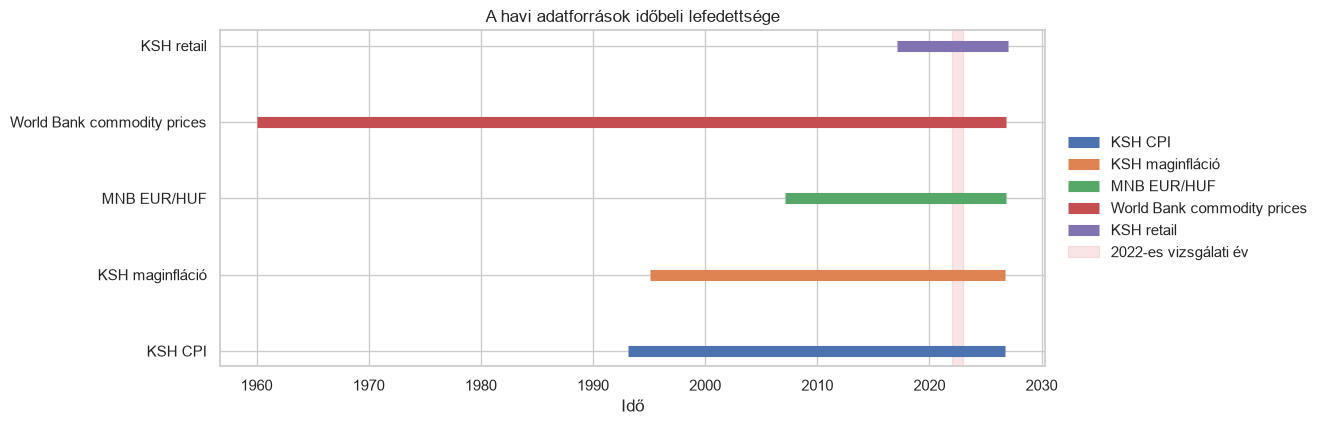

In [5]:
coverage = audit.set_index("forrás")[["első dátum", "utolsó dátum"]].copy()
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (name, row) in enumerate(coverage.iterrows()):
    start, end = pd.to_datetime(row["első dátum"]), pd.to_datetime(row["utolsó dátum"])
    ax.plot([start, end], [i, i], lw=8, solid_capstyle="butt", label=name)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#E15759", alpha=0.15, label="2022-es vizsgálati év")
ax.set_yticks(range(len(coverage)))
ax.set_yticklabels(coverage.index)
ax.set_title("A havi adatforrások időbeli lefedettsége")
ax.set_xlabel("Idő")
ax.set_ylabel("")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=False, borderaxespad=0)
fig.subplots_adjust(right=0.76, bottom=0.18)
plt.show()

## 5. EDA II. – Nemzetközi energiaárak és magyar infláció

A kétpaneles ábra külön skálán mutatja az energiaárak szintjét és a magyar infláció éves változását. A szintek eltérő mértékegysége miatt nem szabad őket egyetlen közös y-tengelyen összehasonlítani. A következő kutatási lépésben ezért változásokat és késleltetéseket is vizsgálni kell majd.

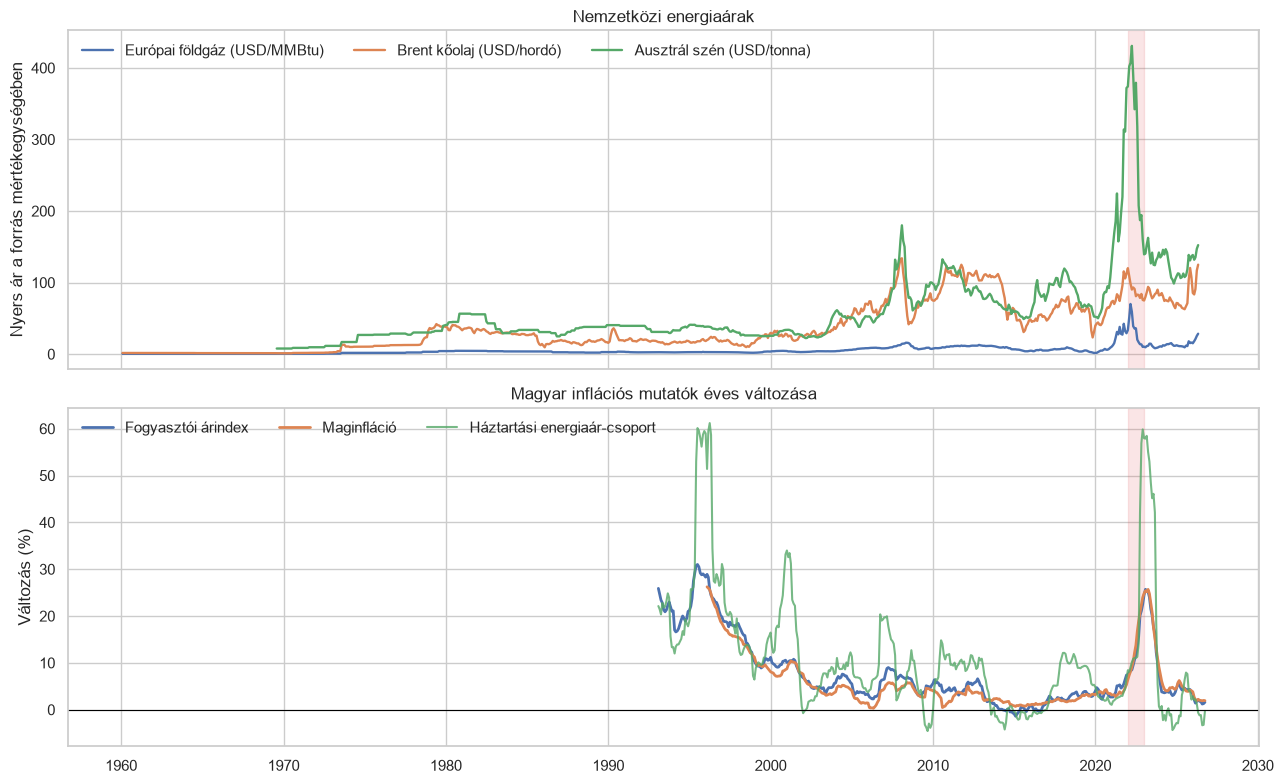

In [6]:
eda = combined.set_index("date").sort_index()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
energy_cols = ["europe_gas_usd_per_mmbtu", "brent_usd_per_bbl", "australian_coal_usd_per_mt"]
energy_labels = {
    "europe_gas_usd_per_mmbtu": "Európai földgáz (USD/MMBtu)",
    "brent_usd_per_bbl": "Brent kőolaj (USD/hordó)",
    "australian_coal_usd_per_mt": "Ausztrál szén (USD/tonna)",
}
for col in energy_cols:
    if col in eda:
        axes[0].plot(eda.index, eda[col], label=energy_labels[col], lw=1.7)
axes[0].axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#E15759", alpha=0.15)
axes[0].set_title("Nemzetközi energiaárak")
axes[0].set_ylabel("Nyers ár a forrás mértékegységében")
axes[0].legend(frameon=False, ncol=3)
axes[1].plot(eda.index, eda["cpi_yoy_pct"], label="Fogyasztói árindex", lw=2)
axes[1].plot(eda.index, eda["core_inflation_yoy_pct"], label="Maginfláció", lw=2)
axes[1].plot(eda.index, eda["household_energy_yoy_pct"], label="Háztartási energiaár-csoport", lw=1.5, alpha=.8)
axes[1].axhline(0, color="black", lw=.8)
axes[1].axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#E15759", alpha=0.15)
axes[1].set_title("Magyar inflációs mutatók éves változása")
axes[1].set_ylabel("Változás (%)")
axes[1].legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 6. EDA III. – Árfolyam, alapkamat és fogyasztási indikátorok

Az energiaválság makrogazdasági értelmezéséhez nem elegendő kizárólag az energiaárakat és az inflációt ábrázolni. Az EUR/HUF árfolyam és az alapkamat a későbbi modellben lehetséges kontrollváltozóként jelenhet meg, a kiskereskedelmi forgalom pedig a háztartási kereslet egyik megfigyelhető indikátora.

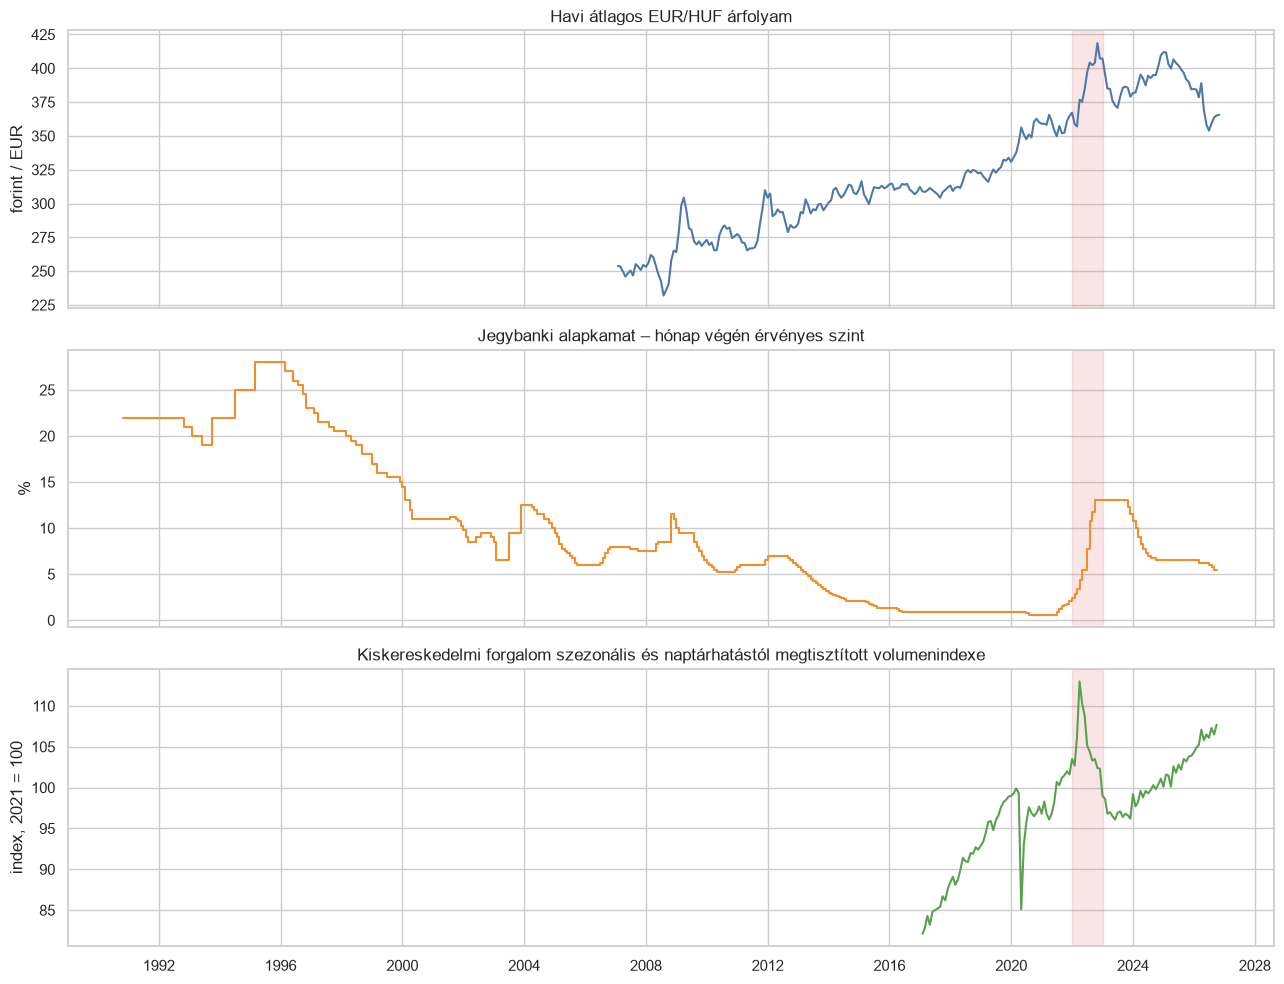

In [7]:
rate_monthly = (
    base_rate_events.set_index("date")["base_rate_pct"]
    .resample("ME").last().ffill().rename("base_rate_pct").to_frame()
    .reset_index()
)
macro = (
    fx.merge(rate_monthly, on="date", how="outer")
    .merge(retail, on="date", how="outer")
    .sort_values("date")
)

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axes[0].plot(macro["date"], macro["eur_huf_monthly_avg"], color="#4E79A7")
axes[0].set_title("Havi átlagos EUR/HUF árfolyam")
axes[0].set_ylabel("forint / EUR")
axes[1].step(macro["date"], macro["base_rate_pct"], where="post", color="#F28E2B")
axes[1].set_title("Jegybanki alapkamat – hónap végén érvényes szint")
axes[1].set_ylabel("%")
axes[2].plot(macro["date"], macro["retail_sa_index"], color="#59A14F")
axes[2].set_title("Kiskereskedelmi forgalom szezonális és naptárhatástól megtisztított volumenindexe")
axes[2].set_ylabel("index, 2021 = 100")
for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#E15759", alpha=0.15)
plt.tight_layout()
plt.show()

## 7. EDA IV. – Kapcsolatok és egyszerű korrelációs áttekintés

Az alábbi ábrák nem regressziós eredmények. A pontdiagramok a változók egyidejű, illetve egy hónappal késleltetett együttmozgását szemléltetik. A Pearson-korreláció érzékeny lehet trendekre, kiugró értékekre és a 2022-es sokkra, ezért a későbbi modellezés előtt differenciálást, késleltetéseket, időszakos becsléseket és robusztussági ellenőrzéseket kell megfontolni.

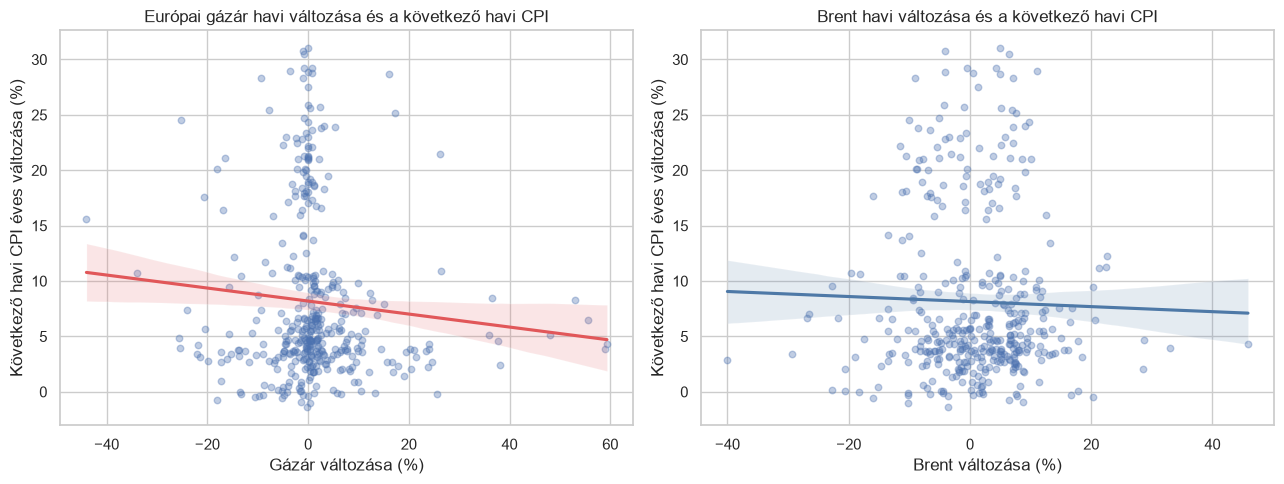

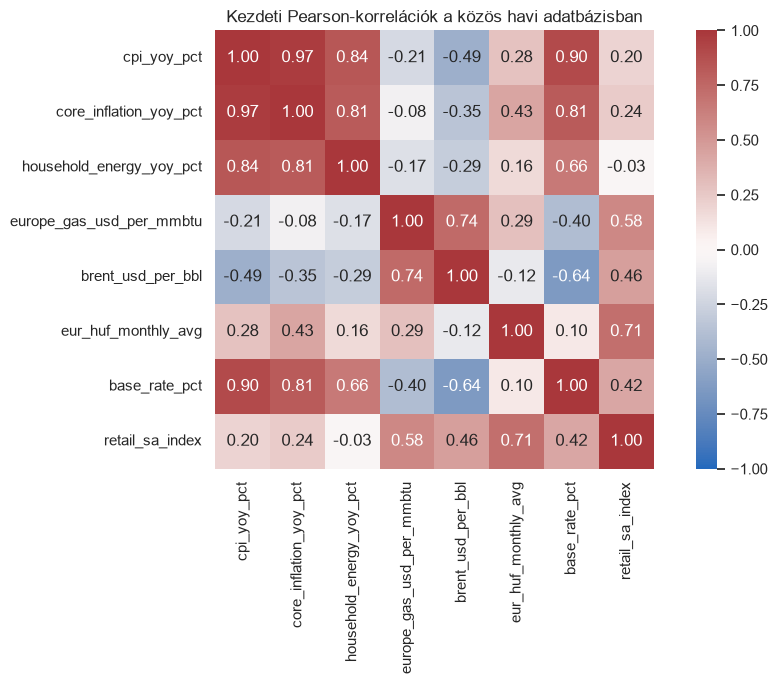

,Fogyasztói árindex éves változása (%),Maginfláció éves változása (%),Háztartási energiaárak éves változása (%),Európai földgáz ára (USD/MMBtu),Brent kőolaj ára (USD/hordó),Havi átlagos EUR/HUF árfolyam,Jegybanki alapkamat (%),Kiskereskedelem szezonálisan és naptárhatással tisztított index
Fogyasztói árindex éves változása (%),1.000,0.975,0.837,-0.214,-0.488,0.284,0.901,0.201
Maginfláció éves változása (%),0.975,1.000,0.814,-0.078,-0.347,0.434,0.813,0.240
Háztartási energiaárak éves változása (%),0.837,0.814,1.000,-0.172,-0.292,0.165,0.662,-0.031
Európai földgáz ára (USD/MMBtu),-0.214,-0.078,-0.172,1.000,0.736,0.292,-0.396,0.580
Brent kőolaj ára (USD/hordó),-0.488,-0.347,-0.292,0.736,1.000,-0.123,-0.636,0.465
Havi átlagos EUR/HUF árfolyam,0.284,0.434,0.165,0.292,-0.123,1.000,0.095,0.711
Jegybanki alapkamat (%),0.901,0.813,0.662,-0.396,-0.636,0.095,1.000,0.424
Kiskereskedelem szezonálisan és naptárhatással tisztított index,0.201,0.240,-0.031,0.580,0.465,0.711,0.424,1.000


In [8]:
plot_df = combined.copy().sort_values("date")
plot_df["gas_change_1m_pct"] = plot_df["europe_gas_usd_per_mmbtu"].pct_change() * 100
plot_df["brent_change_1m_pct"] = plot_df["brent_usd_per_bbl"].pct_change() * 100
plot_df["eur_huf_change_1m_pct"] = plot_df["eur_huf_monthly_avg"].pct_change() * 100
plot_df["cpi_lag1"] = plot_df["cpi_yoy_pct"].shift(-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
if plot_df["gas_change_1m_pct"].notna().any():
    sns.regplot(data=plot_df, x="gas_change_1m_pct", y="cpi_lag1", scatter_kws={"alpha": .35, "s": 22}, line_kws={"color": "#E15759"}, ax=axes[0])
axes[0].set_title("Európai gázár havi változása és a következő havi CPI")
axes[0].set_xlabel("Gázár változása (%)")
axes[0].set_ylabel("Következő havi CPI éves változása (%)")
if plot_df["brent_change_1m_pct"].notna().any():
    sns.regplot(data=plot_df, x="brent_change_1m_pct", y="cpi_lag1", scatter_kws={"alpha": .35, "s": 22}, line_kws={"color": "#4E79A7"}, ax=axes[1])
axes[1].set_title("Brent havi változása és a következő havi CPI")
axes[1].set_xlabel("Brent változása (%)")
axes[1].set_ylabel("Következő havi CPI éves változása (%)")
plt.tight_layout()
plt.show()

corr_cols = [
    "cpi_yoy_pct", "core_inflation_yoy_pct", "household_energy_yoy_pct",
    "europe_gas_usd_per_mmbtu", "brent_usd_per_bbl", "eur_huf_monthly_avg",
    "base_rate_pct", "retail_sa_index",
]
corr = combined.merge(rate_monthly, on="date", how="left")[corr_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Kezdeti Pearson-korrelációk a közös havi adatbázisban")
plt.tight_layout()
plt.show()
display(corr.rename(index=DISPLAY_NAMES, columns=DISPLAY_NAMES).round(3))

## 8. EDA V. – A 2022-es időszak leíró összehasonlítása

A következő táblázat a 2022-es év átlagát hasonlítja össze a 2019-es bázisévvel és a 2023-as évvel. Ez leíró összevetés, nem kezelés–kontroll kísérlet: a 2022-es változásokhoz más párhuzamos gazdasági folyamatok is hozzájárulhattak.

In [9]:
annual_compare = combined.copy()
annual_compare["year"] = annual_compare["date"].dt.year
compare_cols = [
    "cpi_yoy_pct", "core_inflation_yoy_pct", "household_energy_yoy_pct",
    "europe_gas_usd_per_mmbtu", "brent_usd_per_bbl", "eur_huf_monthly_avg",
    "retail_sa_index",
]
available_compare = [c for c in compare_cols if c in annual_compare]
summary_annual = annual_compare[annual_compare["year"].isin([2019, 2022, 2023])].groupby("year")[available_compare].mean().T
summary_annual.columns = [f"{int(col)} átlaga" for col in summary_annual.columns]
summary_annual.index = summary_annual.index.map(DISPLAY_NAMES.get)
display(summary_annual.round(2))

,2019 átlaga,2022 átlaga,2023 átlaga
Fogyasztói árindex éves változása (%),3.35,14.51,17.62
Maginfláció éves változása (%),3.09,15.7,18.17
Háztartási energiaárak éves változása (%),7.67,25.19,35.92
Európai földgáz ára (USD/MMBtu),3.42,31.31,10.77
Brent kőolaj ára (USD/hordó),51.62,86.82,84.72
Havi átlagos EUR/HUF árfolyam,325.35,391.06,381.84
Kiskereskedelem szezonálisan és naptárhatással tisztított index,96.59,105.08,97.02


## 9. Kezdeti következtetések és a következő kutatási lépések

### Mit tudunk most felelősen állítani?

- A források több, egymással összehangolható havi idősorral rendelkeznek, de a lefedettség és a frissesség változó.
- A 2022-es évben az energiaárak, az infláció, az árfolyam és a kamatkörnyezet egyszerre változott, ezért az egyszerű együttmozgás nem azonosítható automatikusan egyetlen ok hatásaként.
- A CPI és a maginfláció különválasztása lehetővé teszi az elsődleges energiaár-hatás és a szélesebb, késleltetett áralkalmazkodás eltérő vizsgálatát.
- A kiskereskedelmi és fogyasztási mutatók alkalmasak lehetnek a reálgazdasági csatorna első leíró vizsgálatára, de az eltérő gyakoriság és indexbázis miatt összehangolásuk indoklást igényel.

### Következő lépések a teljes kutatásban

1. Forrásonkénti változószótár és mértékegység-ellenőrzés.
2. A végleges közös havi mintaperiódus kijelölése.
3. Hiányzó és szélsőséges értékek szakmai ellenőrzése, nem automatikus törlése.
4. Transzformációk és késleltetések előzetes, csak a tanító adaton végzett kiválasztása.
5. Időrendi tanuló–teszt felosztás, hogy a jövőbeli adatok ne szivárogjanak vissza a modellválasztásba.
6. Egyszerű átlagos és lineáris baseline, majd indokolt nemlineáris modell összehasonlítása.
7. Out-of-fold diagnosztika és egy dokumentált visszacsatolási kör.
8. Egyszeri záró teszt, korlátok és óvatos közgazdasági értelmezés.

Az EDA alapján jelenleg **nem szükséges további adat ahhoz, hogy a kutatási tervet és a kezdeti elemzést bemutassuk**. A későbbi modellhez azonban hasznos lehet a hatósági energiaár-intézkedések pontos időpontjainak és a háztartási energiaár-szabályozás releváns változásainak külön adatforrásból történő dokumentálása.